<a href="https://colab.research.google.com/github/cjbugarin/act4-eda-personal-loan/blob/main/Actividad4EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Carlos Joel Bugarín González
*   MATRÍCULA: A01841627

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [2]:
loan_df = pd.read_csv("personal_loan.csv", index_col="ID")
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


**Respuesta:** Sin contar `ID`, que ahora es el índice, el data frame tiene 13 columnas. De las cuales, 8 son numéricas (6 `int64`: `Age`, `Experience`, `Income`, `ZIP Code`, `Family` y `Mortgage`; y 2 `float64`: `CCAvg` y `Education`) y 5 son de texto (`Personal Loan`, `Securities Account`, `CD Account`, `Online` y `CreditCard`).

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [3]:
# Total de registros antes de limpiar
total_inicial = len(loan_df)

# Estadísticas descriptivas de las variables numéricas
display(loan_df.describe())

# Registros con edad mayor a 100 años, y su eliminación
display(loan_df[loan_df["Age"] > 100])
loan_df = loan_df[loan_df["Age"] <= 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [4]:
# Income, CCAvg y Mortgage no deberían ser negativos
display((loan_df[["Income", "CCAvg", "Mortgage"]] < 0).sum())

# Experience debe ser coherente con la edad (se asume que se empieza a trabajar a los 18)
display((loan_df["Experience"] > loan_df["Age"] - 18).sum())

# Experiencia laboral negativa
display(loan_df[loan_df["Experience"] < 0])
loan_df = loan_df[loan_df["Experience"] >= 0]

# Tamaño de familia menor a 1
display(loan_df[loan_df["Family"] < 1])
loan_df = loan_df[loan_df["Family"] >= 1]

# Nivel educativo distinto de 1, 2 o 3
display(loan_df[~loan_df["Education"].isin([1, 2, 3])])
loan_df = loan_df[loan_df["Education"].isin([1, 2, 3])]

# CP con menos de 5 dígitos
display(loan_df[loan_df["ZIP Code"] < 10000])
loan_df = loan_df[loan_df["ZIP Code"] >= 10000]

# Copia limpia para evitar advertencias de pandas al modificar columnas más adelante
loan_df = loan_df.copy()

eliminados = total_inicial - len(loan_df)
print(f"Registros eliminados: {eliminados} ({eliminados / total_inicial * 100:.2f}%)")

,0
Income,0
CCAvg,0
Mortgage,0


np.int64(0)

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No
524,24,-1,75,93014,4,0.20,1.0,0,0,No,No,Yes,0
536,25,-1,43,92173,3,2.40,2.0,176,No,No,0,1,0
540,25,-1,109,94010,4,2.30,3.0,314,0,No,No,1,0
576,25,-1,48,92870,3,0.30,3.0,0,0,No,0,0,1
583,24,-1,38,95045,2,1.70,2.0,0,No,No,No,Yes,0


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
15,60,30,22,95054,-1,1.5,3.0,0,0,No,0,Yes,Yes
3000,40,14,164,94720,-3,4.3,2.0,0,1,No,No,No,No


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
347,25,0,43,94305,2,1.6,7.3,0,0,Yes,Yes,1,Yes


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
384,51,25,21,9307,4,0.6,3.0,0,No,0,0,1,Yes


Registros eliminados: 60 (1.19%)


En el resumen estadístico hay valores que no tienen sentido: `Age` llega a 144 años, `Experience` baja hasta -3, `Family` tiene un mínimo de -3, `Education` llega a 7.3 (solo debería ser 1, 2 o 3) y `ZIP Code` tiene un mínimo de 9307, que no completa los 5 dígitos.

Decisiones tomadas:

* **Edad mayor a 100 años:** se eliminaron 3 registros (123, 130 y 144 años). No son plausibles, ninguna persona llega a esas edades, así que son errores de captura.
* **Experience negativa:** se eliminaron 53 registros con -1, -2 o -3 años. Los años de experiencia laboral no pueden ser negativos.
* **Family inválida:** se eliminaron 2 registros con -3 y -1. El número de miembros de la familia no puede ser negativo y, como incluye al cliente, el mínimo posible es 1.
* **Education fuera de categoría:** se eliminó 1 registro con 7.3. La variable solo admite 1, 2 o 3, y ese valor ni siquiera es entero.
* **ZIP Code incompleto:** se eliminó 1 registro con 9307. Los códigos postales de Estados Unidos tienen 5 dígitos y no hay forma de saber cuál era el valor correcto.
* `Income`, `CCAvg` y `Mortgage` no tienen valores negativos y ningún cliente tiene más años de experiencia de los que alcanzaría trabajando desde los 18, así que no se eliminó nada por esas variables.

**Respuesta:** en total se eliminaron 60 registros, que representan el 1.19% de los 5,037 registros iniciales.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [5]:
# Columnas de texto
txt_cols = loan_df.select_dtypes(exclude="number").columns

# Estadísticas descriptivas
display(loan_df[txt_cols].describe())

# Frecuencia de cada categoría
for col in txt_cols:
    print(f"--- {col} ---")
    print(loan_df[col].value_counts(), "\n")

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


--- Personal Loan ---
Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64 

--- Securities Account ---
Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64 

--- CD Account ---
CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64 

--- Online ---
Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64 

--- CreditCard ---
CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64 



In [6]:
# Unificar los formatos: 1 = sí y 0 = no, como indica la descripción de las variables
equivalencias = {"Yes": 1, "No": 0, "1": 1, "0": 0}
for col in txt_cols:
    loan_df[col] = loan_df[col].map(equivalencias)

# Verificación
for col in txt_cols:
    print(col, loan_df[col].value_counts().to_dict())

Personal Loan {0: 4492, 1: 485}
Securities Account {0: 4458, 1: 519}
CD Account {0: 4674, 1: 303}
Online {1: 2975, 0: 2002}
CreditCard {0: 3513, 1: 1464}


Las 5 columnas de texto tienen 4 categorías cada una, porque el mismo dato binario venía escrito de cuatro formas: "0", "1", "No" y "Yes". Se unificaron convirtiendo "Yes" y "1" en 1, y "No" y "0" en 0, que es lo que indica la descripción de las variables.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [7]:
# Registros duplicados (se comparan todas las columnas; el ID es el índice y no cuenta)
print("Registros duplicados:", loan_df.duplicated().sum())

# Eliminar duplicados y reiniciar el índice para tener una secuencia continua
loan_df = loan_df.drop_duplicates()
loan_df = loan_df.reset_index(drop=True)
loan_df.shape

Registros duplicados: 36


(4941, 13)

Sí había registros duplicados: se encontraron 36 y se eliminaron. El dataframe quedó con 4,941 registros y el índice reiniciado de 0 a 4940.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [8]:
# Nominal: ZIP Code como object
loan_df["ZIP Code"] = loan_df["ZIP Code"].astype(str).astype("object")

# Ordinal: Education como category con orden 1 < 2 < 3
loan_df["Education"] = pd.Categorical(loan_df["Education"].astype(int),
                                      categories=[1, 2, 3], ordered=True)

# Binarias como category
for col in ["Personal Loan", "Securities Account", "CD Account", "Online", "CreditCard"]:
    loan_df[col] = loan_df[col].astype("category")

# Listas de variables numéricas y categóricas
num_cols = loan_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = loan_df.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

print(num_cols)
print(cat_cols)
loan_df.info()

['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4941 entries, 0 to 4940
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Age                 4941 non-null   int64   
 1   Experience          4941 non-null   int64   
 2   Income              4941 non-null   int64   
 3   ZIP Code            4941 non-null   object  
 4   Family              4941 non-null   int64   
 5   CCAvg               4941 non-null   float64 
 6   Education           4941 non-null   category
 7   Mortgage            4941 non-null   int64   
 8   Personal Loan       4941 non-null   category
 9   Securities Account  4941 non-null   category
 10  CD Account          4941 non-null   category
 11  Online              4941 non-null   category
 12  CreditCard          49

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [9]:
# Estadísticas descriptivas con simetría (skew) y curtosis (kurt)
resumen = loan_df[num_cols].describe().T
resumen["skew"] = loan_df[num_cols].skew()
resumen["kurt"] = loan_df[num_cols].kurt()
display(resumen)

,count,mean,std,min,25%,50%,75%,max,skew,kurt
Age,4941.0,45.560210,11.315617,24.0,36.0,46.0,55.0,67.0,-0.022754,-1.161599
Experience,4941.0,20.335357,11.308351,0.0,11.0,20.0,30.0,43.0,-0.015216,-1.134857
Income,4941.0,73.826553,46.106768,8.0,39.0,64.0,98.0,224.0,0.841991,-0.046164
Family,4941.0,2.391621,1.148244,1.0,1.0,2.0,3.0,4.0,0.159463,-1.403842
CCAvg,4941.0,1.935855,1.748406,0.0,0.7,1.5,2.6,10.0,1.594670,2.635545
Mortgage,4941.0,56.663631,101.875349,0.0,0.0,0.0,101.0,635.0,2.103865,4.760021


La curtosis que calcula pandas es el exceso de curtosis, así que una normal vale 0.

* **Age** (asimetría -0.02, curtosis -1.16): es prácticamente simétrica y platicúrtica, es decir, más plana que una normal y con colas ligeras.
* **Income** (asimetría 0.84, curtosis -0.05): tiene asimetría positiva moderada (cola hacia la derecha) y es mesocúrtica, con un apuntamiento similar al de una normal.
* **Mortgage** (asimetría 2.10, curtosis 4.76): tiene asimetría positiva fuerte y es leptocúrtica, muy apuntada y con colas pesadas.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

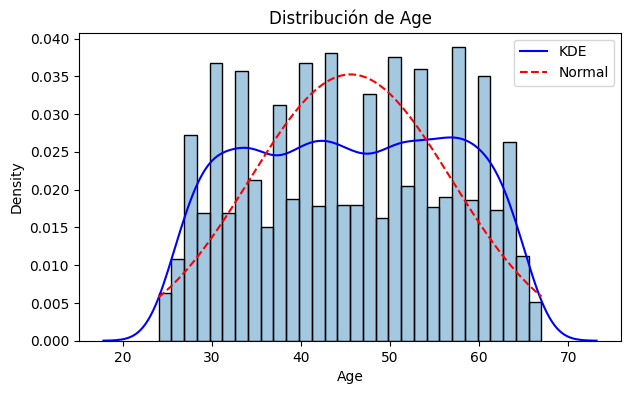

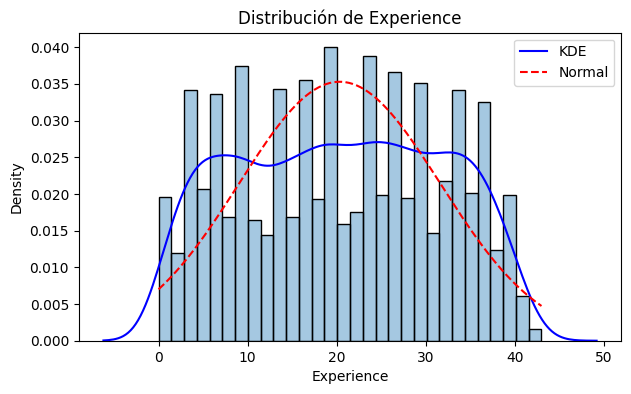

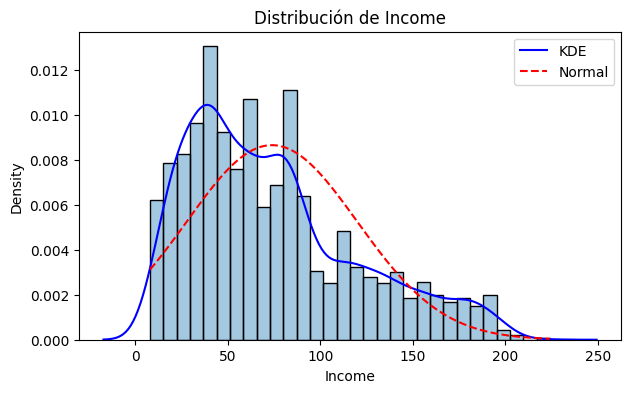

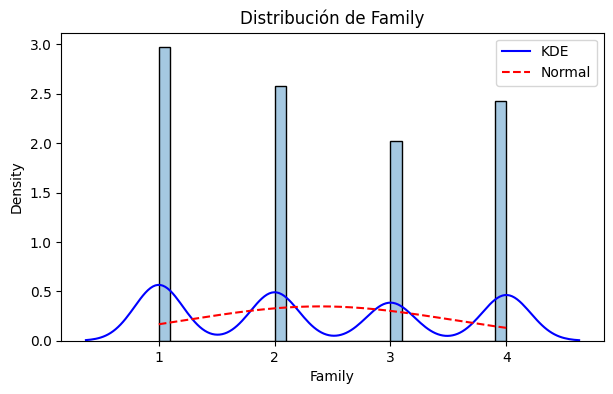

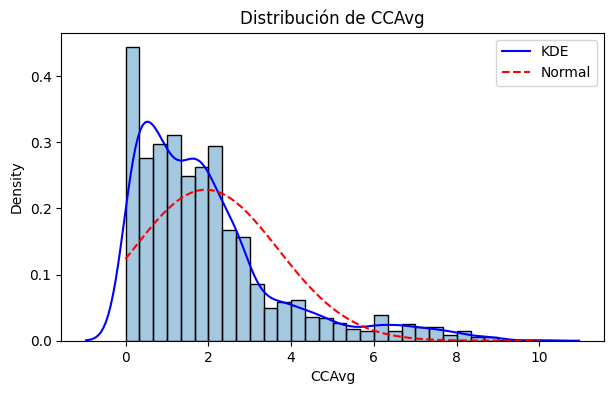

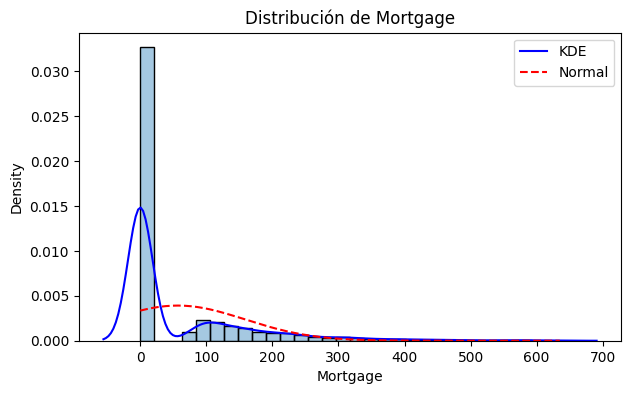

In [10]:
# Histograma + KDE + curva normal de referencia para cada variable numérica
for col in num_cols:
    plt.figure(figsize=(7, 4))
    media, desv = loan_df[col].mean(), loan_df[col].std()
    x = np.linspace(loan_df[col].min(), loan_df[col].max(), 200)

    sns.histplot(loan_df[col], stat="density", bins=30, alpha=0.4)
    sns.kdeplot(loan_df[col], color="blue", label="KDE")
    plt.plot(x, norm.pdf(x, media, desv), color="red", linestyle="--", label="Normal")

    plt.title(f"Distribución de {col}")
    plt.legend()
    plt.show()

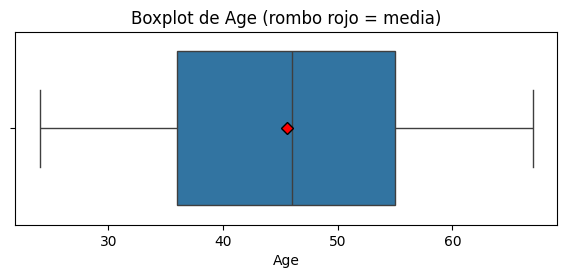

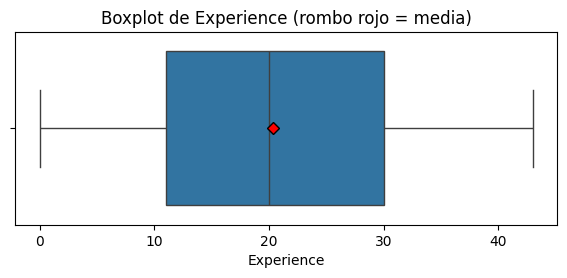

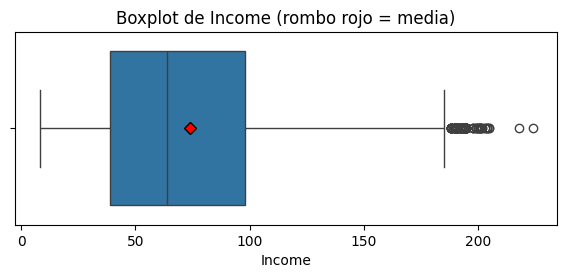

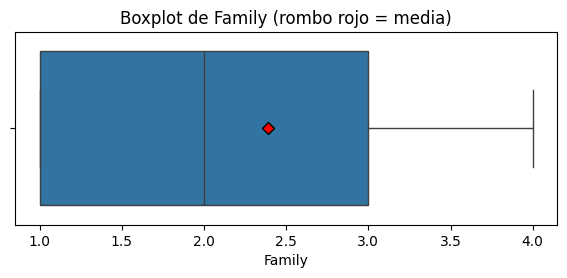

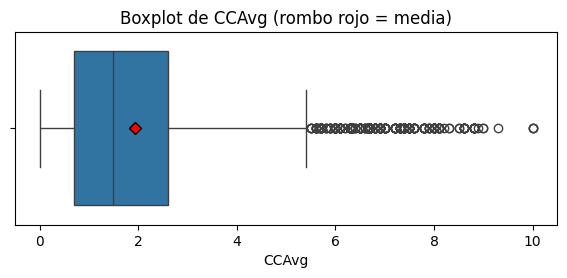

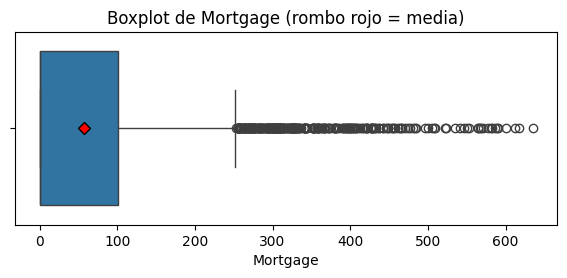

,mean,median,media - mediana
Age,45.560210,46.0,-0.439790
Experience,20.335357,20.0,0.335357
Income,73.826553,64.0,9.826553
Family,2.391621,2.0,0.391621
CCAvg,1.935855,1.5,0.435855
Mortgage,56.663631,0.0,56.663631


In [11]:
# Boxplot individual con la media marcada (rombo rojo)
for col in num_cols:
    plt.figure(figsize=(7, 2.5))
    sns.boxplot(x=loan_df[col], showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "black"})
    plt.title(f"Boxplot de {col} (rombo rojo = media)")
    plt.show()

# Media contra mediana
comparacion = loan_df[num_cols].agg(["mean", "median"]).T
comparacion["media - mediana"] = comparacion["mean"] - comparacion["median"]
display(comparacion)

**Comparación con los valores de la pregunta 6:**

* **Age:** el histograma es plano, con barras de altura parecida en todo el rango de 24 a 67 años y sin la forma de campana de la normal. Coincide con una asimetría casi nula y con la curtosis negativa.
* **Income:** se concentra en ingresos bajos (el pico está cerca de 40) y tiene una cola larga hacia la derecha hasta 224. Coincide con la asimetría positiva moderada. Los boxplots muestran además muchos valores atípicos altos.
* **Mortgage:** hay un pico enorme en 0 (cerca del 69% de los clientes no tiene hipoteca) y una cola que llega hasta 635. Coincide con la asimetría fuerte y la curtosis alta.

**Media contra mediana:** en `Age` la media (45.56) casi es igual a la mediana (46), lo que indica simetría. En `Income` la media (73.83) es mayor que la mediana (64), y en `Mortgage` la diferencia es todavía más grande (56.66 contra 0). Cuando la media queda por encima de la mediana, los valores extremos altos la jalan hacia la derecha, lo que indica asimetría positiva. Si fuera al revés, indicaría asimetría negativa, y si son casi iguales, simetría.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


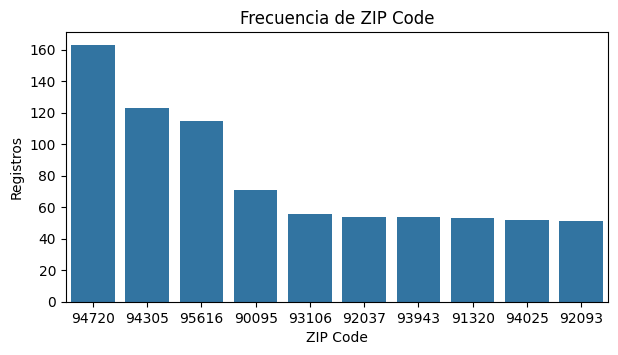

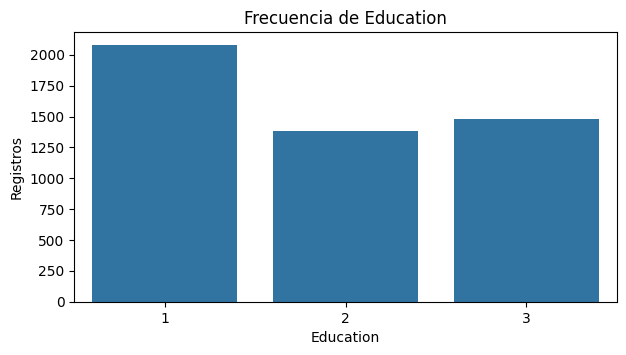

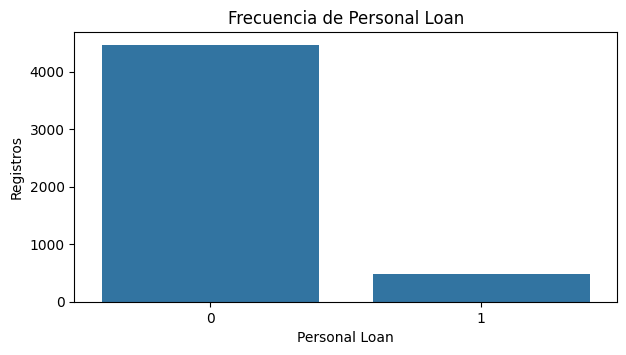

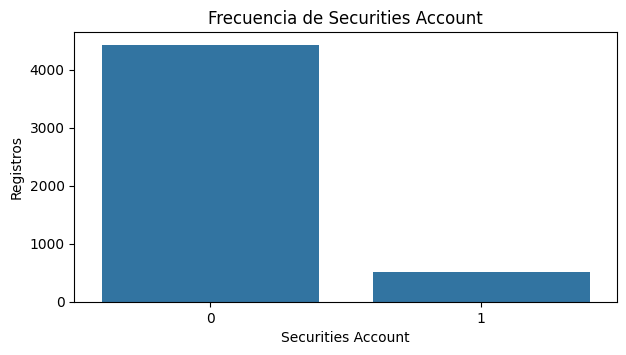

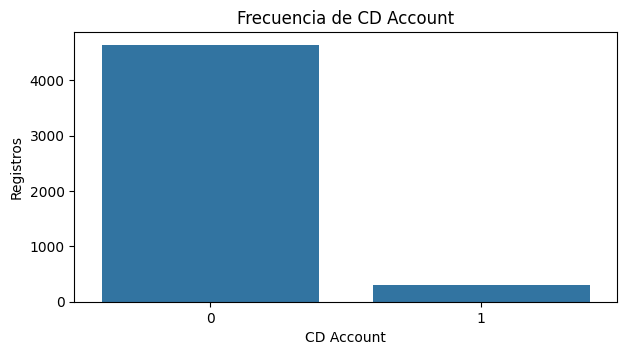

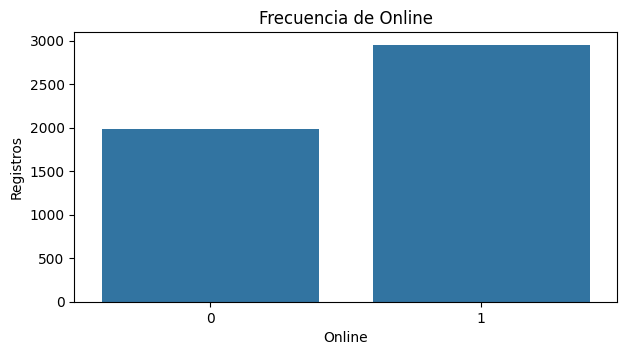

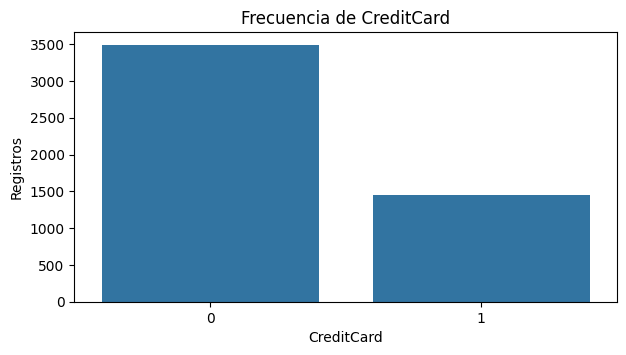

In [12]:
# Estadísticas descriptivas de las variables categóricas
display(loan_df[cat_cols].describe())

# Gráfico de barras para cada una (en las de alta cardinalidad, solo los 10 valores más frecuentes)
for col in cat_cols:
    conteo = loan_df[col].value_counts()
    if loan_df[col].nunique() > 10:
        conteo = conteo.head(10)
    else:
        conteo = conteo.sort_index()

    plt.figure(figsize=(7, 3.5))
    sns.barplot(x=conteo.index.astype(str), y=conteo.values)
    plt.title(f"Frecuencia de {col}")
    plt.xlabel(col)
    plt.ylabel("Registros")
    plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

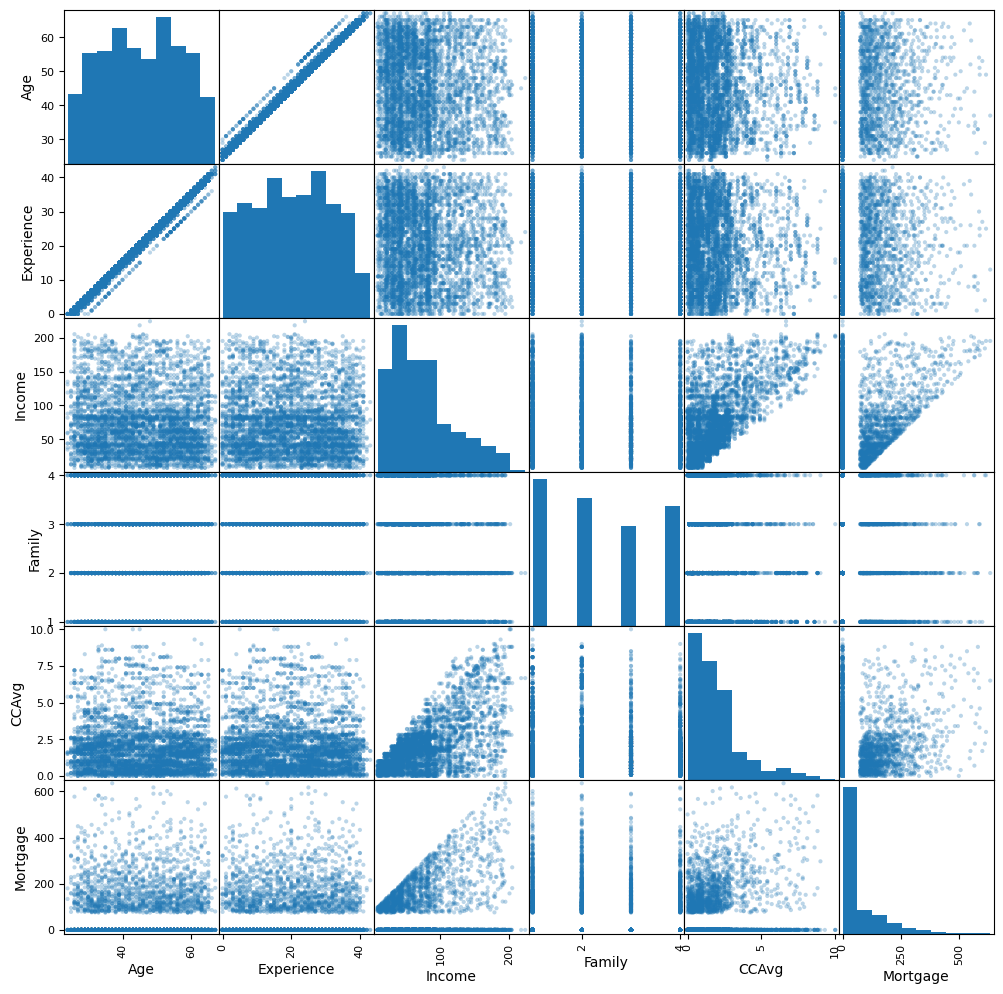

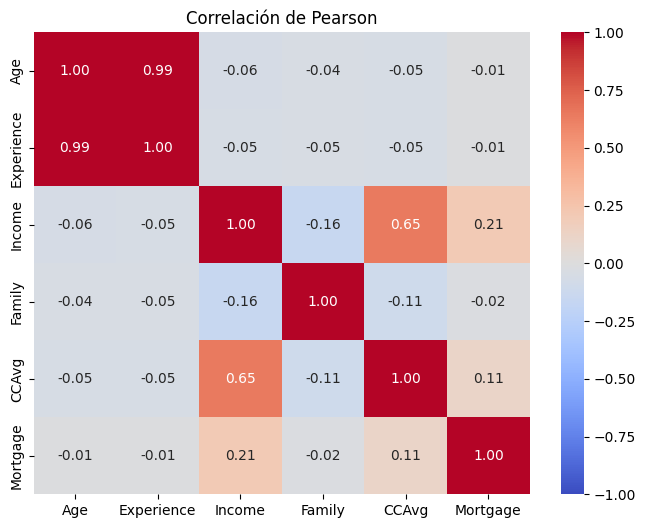

In [13]:
# Matriz de gráficos de dispersión
pd.plotting.scatter_matrix(loan_df[num_cols], figsize=(12, 12), alpha=0.3, diagonal="hist")
plt.show()

# Mapa de calor con la correlación de Pearson
plt.figure(figsize=(8, 6))
sns.heatmap(loan_df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación de Pearson")
plt.show()

El par que elegí es `Age` y `Experience`. En la matriz de dispersión los puntos forman casi una línea recta ascendente: a mayor edad, más años de experiencia, con muy poca dispersión.

El mapa de calor da una correlación de Pearson de 0.99 para este par, que corresponde con lo esperado: una relación lineal positiva muy fuerte, porque la experiencia laboral crece prácticamente al mismo ritmo que la edad.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


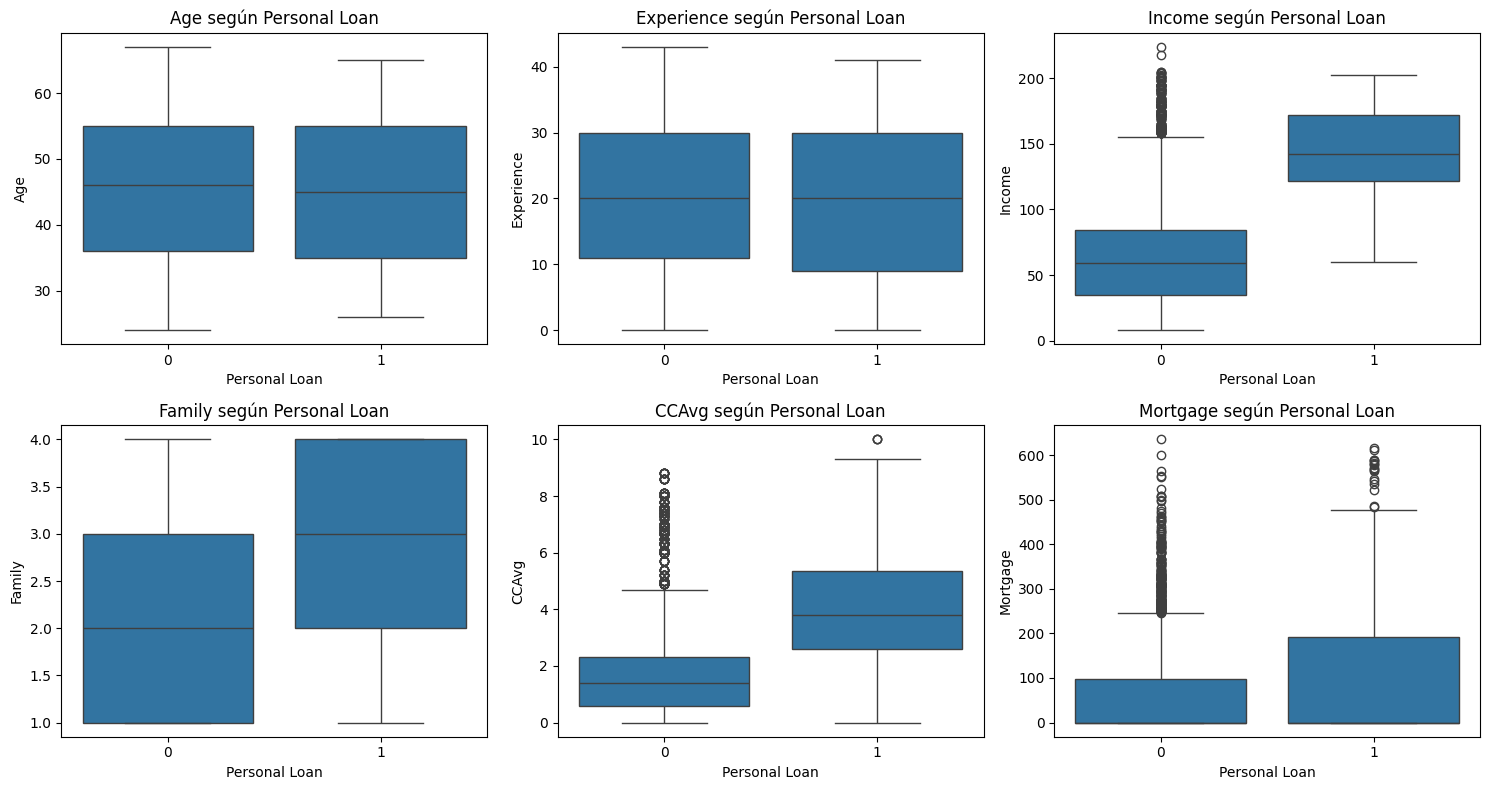

,Age,Experience,Income,Family,CCAvg,Mortgage
Personal Loan,,,,,,
0,46.0,20.0,59.0,2.0,1.4,0.0
1,45.0,20.0,142.0,3.0,3.8,0.0


In [14]:
# Boxplots de cada variable numérica según Personal Loan
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=loan_df, x="Personal Loan", y=col, ax=ax)
    ax.set_title(f"{col} según Personal Loan")
plt.tight_layout()
plt.show()

# Medianas por grupo (apoyan la lectura de los boxplots)
display(loan_df.groupby("Personal Loan", observed=True)[num_cols].median())

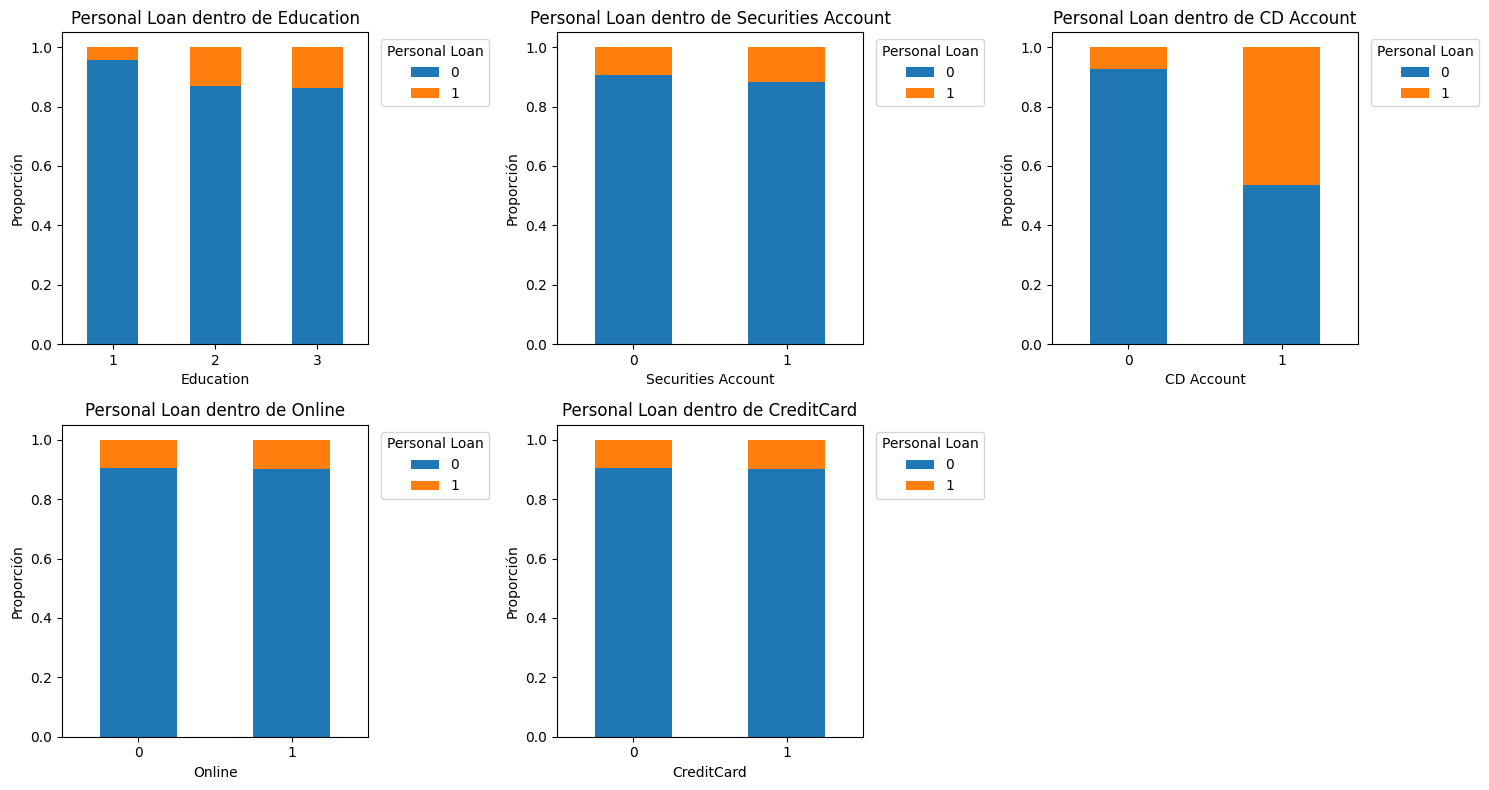

Personal Loan      0      1
Education                  
1              0.955  0.045
2              0.869  0.131
3              0.861  0.139 

Personal Loan           0      1
Securities Account              
0                   0.905  0.095
1                   0.883  0.117 

Personal Loan      0      1
CD Account                 
0              0.927  0.073
1              0.535  0.465 

Personal Loan      0      1
Online                     
0              0.906  0.094
1              0.901  0.099 

Personal Loan      0      1
CreditCard                 
0              0.904  0.096
1              0.902  0.098 



In [15]:
# Barras apiladas: proporción de Personal Loan dentro de cada categoría
cat_bin = [c for c in cat_cols if c not in ["ZIP Code", "Personal Loan"]]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cat_bin):
    prop = pd.crosstab(loan_df[col], loan_df["Personal Loan"], normalize="index")
    prop.plot(kind="bar", stacked=True, ax=ax, rot=0)
    ax.set_title(f"Personal Loan dentro de {col}")
    ax.set_ylabel("Proporción")
    ax.legend(title="Personal Loan", bbox_to_anchor=(1.02, 1), loc="upper left")
axes.ravel()[-1].axis("off")  # el sexto cuadro queda vacío
plt.tight_layout()
plt.show()

# Proporciones exactas
for col in cat_bin:
    print(pd.crosstab(loan_df[col], loan_df["Personal Loan"], normalize="index").round(3), "\n")

**Variables numéricas:** `Income` y `CCAvg` son las que más separan a los dos grupos. Los clientes que aceptaron el préstamo tienen una mediana de ingreso de 142 mil dólares contra 59 mil de quienes no lo aceptaron, y un gasto mensual con tarjeta de 3.8 mil contra 1.4 mil. En cambio, `Age` y `Experience` casi no cambian entre grupos (medianas de 46 y 45 años, y de 20 años de experiencia en ambos), así que por sí solas no distinguen quién acepta.

**Variables categóricas:** `CD Account` es el patrón más claro: entre quienes tienen cuenta de certificado de depósito acepta el préstamo el 46.5%, contra 7.3% entre quienes no la tienen. En `Education`, quienes tienen nivel 1 aceptan en 4.5%, mientras que en los niveles 2 y 3 sube a 13.1% y 13.9%. `Online` y `CreditCard` casi no cambian la proporción (alrededor de 9.5% a 10% en ambas categorías).

---

**Declaración de uso de IA**

Anthropic. (2026). *Claude (Claude Sonnet 5.5)* [Modelo de lenguaje grande], utilizado para depuración de código y como apoyo en la validación de pruebas en cada pregunta. https://claude.ai/

---